In [22]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_fscore_support
import numpy as np

In [ ]:


DATA = "C:/Users/Baxe/Documents/Uni/Socialgraphs/Project/Politics-Network/data/"

# ───────────── 1. Indlæs mærkesagerne fra hjemmesiderne ─────────────

mk = pd.read_csv(DATA + "party_policies_2022/output/policy_pages.csv")
mk["usikker_dato"] = mk["capture_gap_status"] == "substantial_gap"

SKRIVEFORM = {
    "NB": "Mange korte forslag",
    "RV": "Afsnit fra valgoplæg",
    "ALT": "Afsnit fra valgoplæg"
}

mk["skriveform"] = mk["party_code"].map(SKRIVEFORM).fillna("Klare overskrifter")

# Fjern dokumenter uden tekst
mk = mk.dropna(subset=["text"]).copy()
mk = mk[mk["text"].str.strip().ne("")].reset_index(drop=True)
mk["document_id"] = mk.index


# ───────────── 2. Ordlister for de 8 kategorier ─────────────
# "ord" = ord der starter med det · "*ord" = må stå inde i et ord · "=ord" = kun præcis det ord
KATEGORIER = {
    "Sundhed og ældrepleje": ["sundhed", "sygehus", "hospital", "sygeplejersk", "*læge", "*venteliste", "ventetid",
        "psykiatri", "patient", "behandling", "ældre", "plejehjem", "hjemmehjælp", "ældrepleje", "værdig"],
    "Klima og miljø": ["forurening","*klima", "grøn", "co2", "*energi", "vindmølle", "solcelle", "atomkraft", "fossil", "udledning",
        "omstilling", "landbrug", "miljø", "natur", "biodiversitet", "dyrevelfærd", "drikkevand", "*vand"],
    "Skoler og børnepasning": ["kultur","*skole", "uddannelse", "*gymnasi", "elever", "studerende", "=su", "daginstitution",
        "børnehave", "vuggestue", "pædagog", "normering", "minimumsnormering", "lærer", "universitet", "faglært"],
    "Økonomi og skat": ["økonomi", "*skat", "afgift", "inflation", "*pris", "vækst", "virksomhed", "erhverv",
        "iværksætter", "fradrag", "regning", "elafgift", "bureaukrati", "regler", "arbejdsmarked", "løn"],
    "Flygtninge og indvandrere": ["udlænding", "*asyl", "flygtning", "indvandr", "integration", "statsborgerskab",
        "hjemsend", "udvis", "familiesammenfør", "islam", "muslim", "grænse", "opholdstilladelse"],
    "Retspolitik og tryghed": ["kriminal", "straf", "politi", "vold", "bande", "fængsel", "domstol", "tryghed",
        "retssikkerhed", "retsstat", "retspolitik", "offer", "terror"],
    "Forsvar og sikkerhed": ["forsvar", "nato", "militær", "soldat", "værnepligt", "sikkerhedspolitik", "ukraine",
        "rusland", "=krig", "beredskab"],
    "Pension og tilbagetrækning": ["pension", "efterløn", "=arne", "seniorpension", "tilbagetrækning", "pensionist", "folkepension", "alderdom", "pensionsalder"],
}

def rammer(word, stem):
    if stem.startswith("="):
        return word == stem[1:]
    if stem.startswith("*"):
        return stem[1:] in word
    return word.startswith(stem)


def tael(text):
    """Optæl ordmatch inden for hver kategori."""
    words = re.findall(r"[a-zæøåé0-9]+", str(text).lower())

    return {
        category: sum(
            any(rammer(word, stem) for stem in stems)
            for word in words
        )
        for category, stems in KATEGORIER.items()
    }


# ───────────── 3. Opdeling i tekstsegmenter ─────────────

def split_sentences(text):
    # Beskyt almindelige forkortelser mod sætningsopdeling
    text = re.sub(
        r"\b(kr|mio|mia|ca|kl|nr|jf|hhv|bl\.a|f\.eks|dvs|pct)\.",
        lambda match: match.group().replace(".", "<DOT>"),
        str(text),
        flags=re.IGNORECASE
    )

    sentences = re.split(r"(?<=[.!?])\s+|\n+", text)

    return [
        sentence.replace("<DOT>", ".").strip()
        for sentence in sentences
        if sentence.strip()
    ]


df_sentences = mk[
    ["document_id", "party", "party_code", "skriveform",
     "title", "text", "usikker_dato"]
].copy()

df_sentences["sentence"] = df_sentences["text"].apply(split_sentences)

df_sentences = df_sentences.explode(
    "sentence", ignore_index=True
).dropna(subset=["sentence"])

df_sentences["is_heading"] = (
    df_sentences["sentence"].str.startswith("#")
)

df_sentences["n_words"] = (
    df_sentences["sentence"].str.split().str.len()
)


# ───────────── 4. Rensning og deduplikering ─────────────

df_clean = df_sentences.copy()

# Normaliser tekst til identifikation af gentagelser
df_clean["normalized_sentence"] = (
    df_clean["sentence"]
    .str.lower()
    .str.replace(r"^[#*\-\s]+", "", regex=True)
    .str.replace(r"[^\w\s]", "", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identificer irrelevant hjemmesideindhold
boilerplate_patterns = [
    r"tilmeld nyhedsbrev",
    r"har du læst mortens seneste nyhedsbrev",
    r"giv et bidrag",
    r"^er du enig$",
    r"^lad os tale politik$",
    r"vær med til at støtte blå bloks bløde hjerte",
    r"se flere mærkesager og politikområder her",
    r"^aktuelt$",
    r"^radikale forslag$",
    r"^kr$",
    r"^kroner$",
    r"^\d+$"
]

df_clean["is_boilerplate"] = (
    df_clean["normalized_sentence"]
    .str.contains(
        "|".join(boilerplate_patterns),
        regex=True,
        na=False
    )
)

# Fjern irrelevant hjemmesideindhold og tomme segmenter
df_clean = df_clean[
    ~df_clean["is_boilerplate"]
    & df_clean["normalized_sentence"].ne("")
].copy()

# Prioriter dokumenter uden substantial_gap ved gentagelser
df_clean = df_clean.sort_values("usikker_dato", kind="stable")

# Fjern identiske tekstsegmenter inden for samme parti
df_clean = df_clean.drop_duplicates(
    subset=["party_code", "normalized_sentence"]
).reset_index(drop=True)

df_clean["segment_id"] = df_clean.index


# ───────────── 5. Multi-label-klassifikation ─────────────

# Optæl ordmatch pr. tekstsegment
sentence_matches = pd.DataFrame(
    df_clean["sentence"].apply(tael).tolist(),
    index=df_clean.index
)

# Giv ét point i hver kategori med mindst ét ordmatch
sentence_scores = (sentence_matches > 0).astype(int)

df_classified = pd.concat(
    [df_clean, sentence_scores],
    axis=1
)

# Antal kategorier pr. tekstsegment
df_classified["n_categories"] = sentence_scores.sum(axis=1)

# Saml de identificerede kategorier
df_classified["categories"] = sentence_scores.apply(
    lambda row: row.index[row == 1].tolist(),
    axis=1
)

# Segmenter uden match placeres i Andet
df_classified["categories"] = df_classified["categories"].apply(
    lambda categories: categories if categories else ["Andet"]
)

# Én række pr. tekstsegment og kategori
df_long = (
    df_classified.explode("categories", ignore_index=True)
    .rename(columns={"categories": "kategori"})
)


# ───────────── 6. Overblik ─────────────

print(f"Antal dokumenter: {len(mk)}")
print(f"Antal partier: {mk['party_code'].nunique()}")
print(f"Tekstsegmenter før rensning: {len(df_sentences)}")
print(f"Tekstsegmenter efter rensning: {len(df_classified)}")
print(f"Fjernede tekstsegmenter: {len(df_sentences) - len(df_classified)}")

print("\nAntal tekstsegmenter pr. kategori:")
print(df_long["kategori"].value_counts().to_string())


# ───────────── 7. Eksport ─────────────

df_long[
    ["document_id", "segment_id", "party", "party_code",
     "skriveform", "title", "kategori", "sentence",
     "n_categories", "usikker_dato", "is_heading", "text"]
].to_csv(
    DATA + "maerkesager_klassificeret.csv",
    index=False,
    encoding="utf-8-sig"
)

Antal dokumenter: 184
Antal partier: 12
Tekstsegmenter før rensning: 5172
Tekstsegmenter efter rensning: 4753
Fjernede tekstsegmenter: 419

Antal tekstsegmenter pr. kategori:
kategori
Andet                         2079
Økonomi og skat                712
Klima og miljø                 636
Retspolitik og tryghed         539
Sundhed og ældrepleje          477
Skoler og børnepasning         405
Flygtninge og indvandrere      272
Pension og tilbagetrækning      65
Forsvar og sikkerhed            53


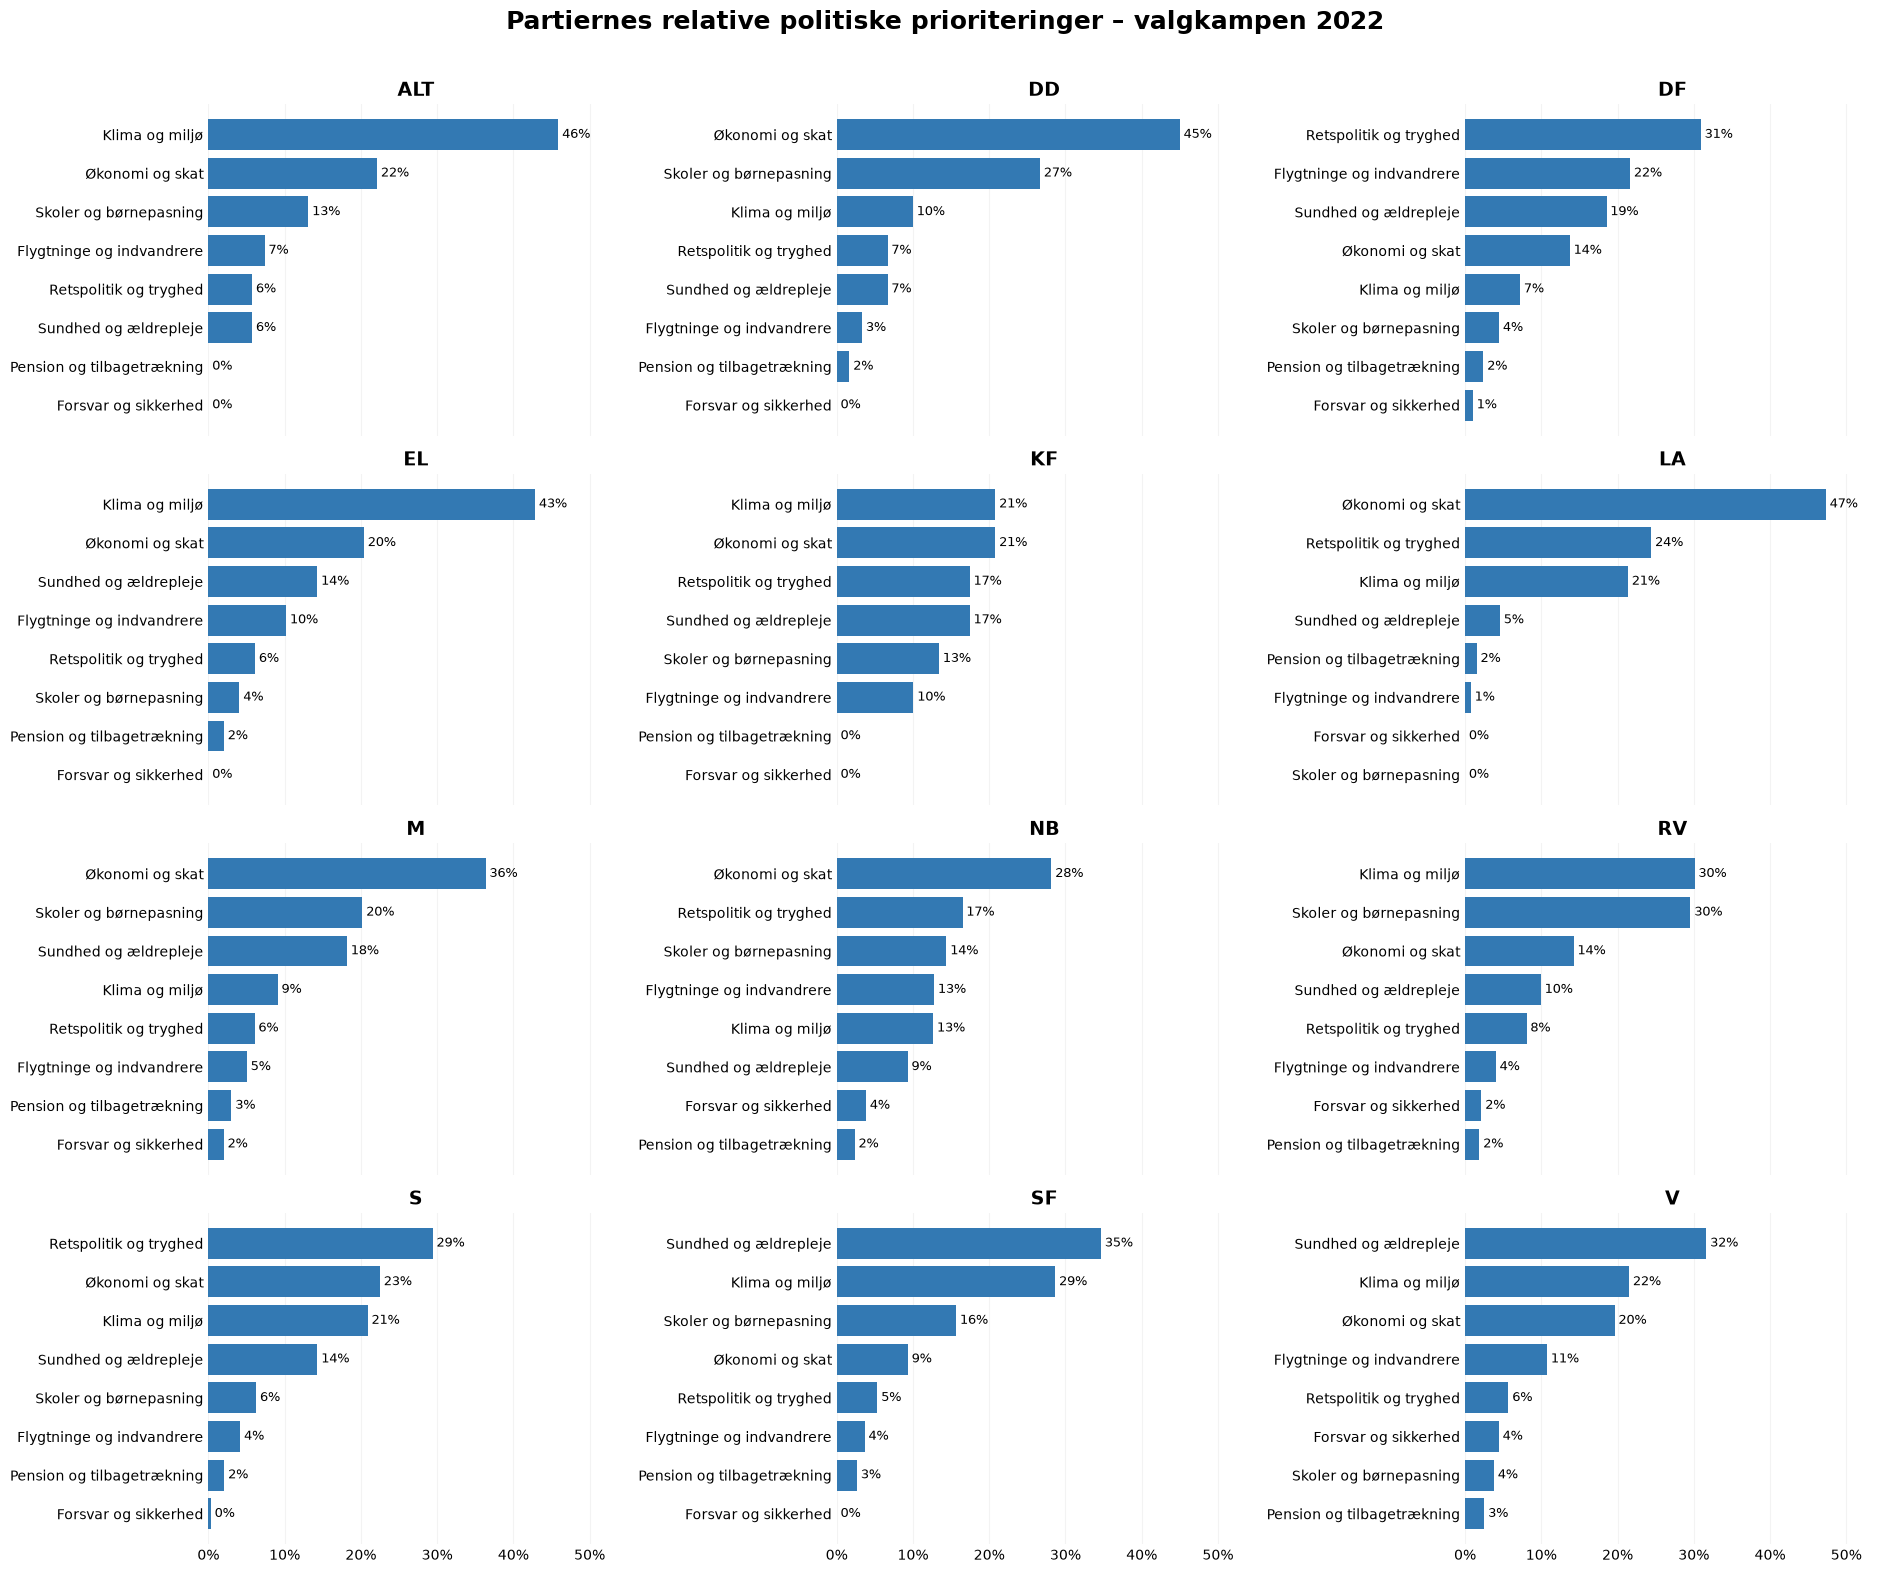

In [17]:
# ───────────── Partiernes individuelle politiske profiler ─────────────

# Fjern tekstsegmenter uden identificeret kategori
mk_plot = df_long[df_long["kategori"] != "Andet"].copy()

# Beregn den relative fordeling af kategoripoint pr. parti
andel = pd.crosstab(
    mk_plot["party_code"],
    mk_plot["kategori"],
    normalize="index"
).reindex(columns=list(KATEGORIER), fill_value=0)

# Opret ét søjlediagram pr. parti
parties = andel.index.tolist()

n_cols = 3
n_rows = (len(parties) + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(19, 4 * n_rows),
    sharex=True
)

axes = axes.flatten()

# Fælles aksegrænse for alle partier
xmax = andel.values.max() * 1.15

for ax, party in zip(axes, parties):

    # Sorter kategorier efter deres andel
    profile = andel.loc[party].sort_values(ascending=True)

    bars = ax.barh(
        profile.index,
        profile.values,
        color="#3379b3"
    )

    # Vis procentandel ved hver søjle
    for bar, value in zip(bars, profile.values):
        ax.text(
            value + 0.005,
            bar.get_y() + bar.get_height() / 2,
            f"{value:.0%}",
            va="center",
            fontsize=9
        )

    ax.set_title(party, fontsize=14, fontweight="bold")
    ax.set_xlim(0, xmax)

    ax.xaxis.set_major_formatter(
        plt.matplotlib.ticker.PercentFormatter(1)
    )

    ax.grid(axis="x", alpha=0.15)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

# Fjern eventuelle tomme diagrammer
for ax in axes[len(parties):]:
    ax.set_visible(False)

fig.suptitle(
    "Partiernes relative politiske prioriteringer – valgkampen 2022",
    fontsize=18,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(
    DATA + "fig_maerkesager_individuelle_partier.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [18]:
# ───────────── Gem en læsbar CSV med klassificerede tekstsegmenter ─────────────

oversigt = pd.DataFrame({
    "parti": df_long["party"],
    "partikode": df_long["party_code"],
    "maerkesag": df_long["title"].str.strip(),
    "kategori": df_long["kategori"],
    "tekstsegment": df_long["sentence"],
    "antal_kategorier": df_long["n_categories"],
    "usikker_dato": df_long["usikker_dato"].map({True: "ja", False: ""}),
    "kilde": df_long["document_id"].map(
        mk.set_index("document_id")["archive_url"]
    )
}).sort_values(["partikode", "kategori", "maerkesag"])

oversigt.to_csv(
    DATA + "maerkesager_2022.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print(f"Gemt: {DATA}maerkesager_2022.csv ({len(oversigt)} rækker)")

display(oversigt)

Gemt: C:/Users/Baxe/Documents/Uni/Socialgraphs/Project/Politics-Network/data/maerkesager_2022.csv (5238 rækker)


,parti,partikode,maerkesag,kategori,tekstsegment,antal_kategorier,usikker_dato,kilde
2898,Alternativet,ALT,Vores liv,Andet,Vi holder af hverdagen.,0,,https://web.archive.org/web/20221101124245id_/https://alternativet.dk/
2899,Alternativet,ALT,Vores liv,Andet,"Selvom kriserne raser og verden er stor, er der en dagligdag og et liv der s...",0,,https://web.archive.org/web/20221101124245id_/https://alternativet.dk/
2900,Alternativet,ALT,Vores liv,Andet,"Og selvom kriser løses systemisk, leves livet i det daglige, og derfor må vi...",0,,https://web.archive.org/web/20221101124245id_/https://alternativet.dk/
2901,Alternativet,ALT,Vores liv,Andet,"Vi skal styrke rammerne for det gode, frie og trygge liv uanset om du er bar...",0,,https://web.archive.org/web/20221101124245id_/https://alternativet.dk/
2904,Alternativet,ALT,Vores liv,Andet,Lad os sikre at alle får en god start.,0,,https://web.archive.org/web/20221101124245id_/https://alternativet.dk/
...,...,...,...,...,...,...,...,...
3790,Venstre,V,Mere frihed til selv at bestemme,Økonomi og skat,Derfor har Venstre og regeringen fremlagt et udspil til en forenkling af reg...,1,ja,https://web.archive.org/web/20260510114342id_/https://venstre.dk/politik/mae...
3791,Venstre,V,Mere frihed til selv at bestemme,Økonomi og skat,## Bedre vilkår for iværksættere,1,ja,https://web.archive.org/web/20260510114342id_/https://venstre.dk/politik/mae...
3792,Venstre,V,Mere frihed til selv at bestemme,Økonomi og skat,Venstre vil gøre det lettere at være iværksætter og selvstændig i Danmark me...,1,ja,https://web.archive.org/web/20260510114342id_/https://venstre.dk/politik/mae...
3793,Venstre,V,Mere frihed til selv at bestemme,Økonomi og skat,Administrativt bøvl og konkurrenceforvridende skatter skal ned.,1,ja,https://web.archive.org/web/20260510114342id_/https://venstre.dk/politik/mae...


In [19]:
# ───────────── Udvælg tekstsegmenter til manuel validering ─────────────

validation_sample = pd.concat(
    [
        group.sample(
            n=min(10, len(group)),
            random_state=42
        )
        for _, group in df_classified.groupby("party_code")
    ],
    ignore_index=True
)

# Bland rækkefølgen
validation_sample = validation_sample.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Gem modellens klassifikation separat
validation_predictions = validation_sample[
    ["segment_id", "party_code", "sentence"] + list(KATEGORIER)
].copy()

# Opret datasæt til manuel klassifikation
manual_labels = validation_sample[
    ["segment_id", "party_code", "sentence"]
].copy()

# Opret tomme kolonner til manuel klassifikation
for category in KATEGORIER:
    manual_labels[category] = ""

manual_labels.to_csv(
    DATA + "manual_validation.csv",
    sep=";",
    index=False,
    encoding="utf-8-sig"
)

print(f"Antal tekstsegmenter til validering: {len(manual_labels)}")

display(manual_labels)

Antal tekstsegmenter til validering: 120


,segment_id,party_code,sentence,Sundhed og ældrepleje,Klima og miljø,Skoler og børnepasning,Økonomi og skat,Flygtninge og indvandrere,Retspolitik og tryghed,Forsvar og sikkerhed,Pension og tilbagetrækning
0,68,KF,- Investere i barnets første 1.000 dage blandt andet ved at ansætte flere pæ...,,,,,,,,
1,15,KF,For klimaet har brug for handling nu.,,,,,,,,
2,2656,ALT,Derfor vil Alternativet indføre mulighed for en bruttolønsordning for anskaf...,,,,,,,,
3,1965,LA,"Det betyder færre penge til forbrug, ferie og fritid, fordi vi skal finansie...",,,,,,,,
4,2368,DF,Det er ikke i orden.,,,,,,,,
...,...,...,...,...,...,...,...,...,...,...,...
115,1485,SF,"Flere sundhedsplejerskebesøg til småbørn, mere sundhedspleje til udsatte fam...",,,,,,,,
116,2421,DD,"Så derfor foreslår vi i Danmarksdemokraterne, at danske familier får 9 ugers...",,,,,,,,
117,2916,S,Da Socialdemokratiet gik til valg i 2019 var det på det grønne område med en...,,,,,,,,
118,1992,LA,"I LA’s 2035-plan foreslår vi, at få max 40 % i skat ved at fjerne topskatten...",,,,,,,,


In [ ]:

# Indlæs de manuelt gennemgåede kategorier
validation_labels = pd.read_csv(
    DATA + "manual_validation_sdn.csv",
    sep=";",
    encoding="utf-8-sig"
)

# Sammenkobl referencelabels og automatisk klassifikation
validation = validation_labels.merge(
    validation_predictions,
    on="segment_id",
    suffixes=("_manual", "_predicted"),
    validate="one_to_one"
)

# Udtræk de manuelle og automatiske klassifikationer
y_true = validation[
    [f"{cat}_manual" for cat in KATEGORIER]
].astype(int).to_numpy()

y_pred = validation[
    [f"{cat}_predicted" for cat in KATEGORIER]
].astype(int).to_numpy()

# Beregn performance for hver kategori
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

validation_results = pd.DataFrame({
    "category": list(KATEGORIER),    "precision": precision,
    "recall": recall,
    "f1": f1,
    "support": support,
    "predicted_count": y_pred.sum(axis=0)
})

# Markér kategorier, hvor målene ikke kan beregnes
validation_results.loc[
    validation_results["predicted_count"] == 0, "precision"
] = np.nan

validation_results.loc[
    validation_results["support"] == 0, ["recall", "f1"]
] = np.nan

print(f"Antal validerede tekstsegmenter: {len(validation)}")

display(validation_results.round(3))

# Beregn samlet micro-performance
micro = precision_recall_fscore_support(
    y_true,
    y_pred,
    average="micro",
    zero_division=0
)

print(f"Micro precision: {micro[0]:.3f}")
print(f"Micro recall:    {micro[1]:.3f}")
print(f"Micro F1:        {micro[2]:.3f}")



Antal validerede tekstsegmenter: 120


,category,precision,recall,f1,support,predicted_count
0,Sundhed og ældrepleje,0.857,0.706,0.774,17,14
1,Klima og miljø,0.933,0.737,0.824,19,15
2,Skoler og børnepasning,0.875,0.700,0.778,10,8
3,Økonomi og skat,0.895,0.515,0.654,33,19
4,Flygtninge og indvandrere,1.000,1.000,1.000,4,4
5,Retspolitik og tryghed,0.500,0.571,0.533,7,8
6,Forsvar og sikkerhed,1.000,1.000,1.000,1,1
7,Pension og tilbagetrækning,0.500,1.000,0.667,1,2


Micro precision: 0.845
Micro recall:    0.652
Micro F1:        0.736


In [24]:
# Gem valideringsresultater pr. kategori
validation_results.to_csv(
    DATA + "policy_validation_results.csv",
    index=False,
    encoding="utf-8-sig"
)

# Gem samlede valideringsresultater
validation_summary = pd.DataFrame([{
    "n_segments": len(validation),
    "micro_precision": micro[0],
    "micro_recall": micro[1],
    "micro_f1": micro[2]
}])

validation_summary.to_csv(
    DATA + "policy_validation_summary.csv",
    index=False,
    encoding="utf-8-sig"
)